# Hybrid CNN: screening of CNN combinations
Frozen features of five CNNs; logistic regression on every single CNN, pair and triple; ranking on validation macro-F1 over four crops.

## 1. GPU check

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 2. Settings + Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q imagehash
from pathlib import Path
import os, json, time, gc, hashlib, subprocess
import numpy as np, pandas as pd, psutil, imagehash
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold

PROJECT   = Path('/content/drive/MyDrive/thesis')
ZIP_PATH  = PROJECT / 'data/raw/agri_vision.zip'
RICE_ZIP  = PROJECT / 'data/raw/riceleafbd.zip'
CROPS     = ['Tomato', 'Papaya', 'Bottle_Gourd', 'Rice']
MODEL_NAMES = ['VGG16', 'ResNet50', 'DenseNet121', 'InceptionV3', 'ConvNeXtTiny']   # top 5 of the all-crops baseline
FEAT_DIR  = PROJECT / 'experiments' / 'screening' / 'features'    # saved features (re-used after a restart)
SCR_DIR   = PROJECT / 'experiments' / 'screening'
IMG_SIZE  = 224
FOLD, SEED, N_FOLDS = 0, 42, 5
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
print('Agri-Vision zip found:', ZIP_PATH.exists(), '| Rice zip found:', RICE_ZIP.exists())

Mounted at /content/drive
Agri-Vision zip found: True | Rice zip found: True


## 3. Agri-Vision: unzip to local disk

In [3]:
import shutil
UNZIP_DIR = Path('/content/data/agri_vision')
print('Agri-Vision zip found in Drive:', ZIP_PATH.exists(), ZIP_PATH)
assert ZIP_PATH.exists(), 'Zip not found: check the file name and folder in Google Drive'

def find_orig():
    return [p for p in UNZIP_DIR.rglob('*') if p.is_dir() and 'original' in p.name.lower()]

if not find_orig():                      # missing or incomplete unzip -> start again cleanly
    shutil.rmtree(UNZIP_DIR, ignore_errors=True)
    UNZIP_DIR.mkdir(parents=True)
    !unzip -q "{ZIP_PATH}" -d "{UNZIP_DIR}"
    for inner in list(UNZIP_DIR.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"

found = find_orig()
if not found:
    print('Still no "Original" folder. Top folders inside the zip:')
    for p in sorted(UNZIP_DIR.rglob('*')):
        if p.is_dir() and len(p.relative_to(UNZIP_DIR).parts) <= 3:
            print('   ', p.relative_to(UNZIP_DIR))
    raise SystemExit('Original images folder not found')
ORIG_DIR = found[0]
print('Original images folder:', ORIG_DIR)

Agri-Vision zip found in Drive: True /content/drive/MyDrive/thesis/data/raw/agri_vision.zip
Original images folder: /content/data/agri_vision/Agri-Vision4 A Comprehensive Multi-Crop Leaf Disea/Bottle Gourd, Papaya, Tomato, and Zucchini Original Dataset


## 4. Agri-Vision: audit, clean and folds

In [4]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
rows = []
for p in tqdm(sorted(q for q in ORIG_DIR.rglob('*') if q.suffix.lower() in IMG_EXT), desc='Hashing'):
    parts = p.relative_to(ORIG_DIR).parts
    rec = {'rel_path': '/'.join(parts), 'split': parts[0], 'label_raw': parts[-2]}
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            rec['phash'] = str(imagehash.phash(im.convert('RGB')))
        rec['md5'] = hashlib.md5(p.read_bytes()).hexdigest()
        rec['corrupt'] = False
    except Exception:
        rec['corrupt'] = True
    rows.append(rec)
df = pd.DataFrame(rows).sort_values('rel_path').reset_index(drop=True)
df['label'] = df.label_raw.replace({'Tomato_Downy Mildew': 'Tomato_Downy_Mildew', 'Zucchini_Downy_Midew': 'Zucchini_Downy_Mildew'})
df['crop'] = df.label.str.extract(r'^(Bottle_Gourd|Papaya|Tomato|Zucchini)', expand=False)
df['keep'], df['reason'] = True, ''

def drop(mask, reason):
    m = mask & df.keep
    df.loc[m, 'keep'], df.loc[m, 'reason'] = False, reason
    print(f'{reason:24s} removed {int(m.sum()):5d}   remaining {int(df.keep.sum()):5d}')

drop(df.corrupt.astype(bool), 'unreadable')
g = df[df.keep].groupby('md5').label.nunique();   drop(df.md5.isin(g[g > 1].index), 'label_conflict_exact')
drop(df.keep & df.duplicated('md5'), 'duplicate_copy')
g = df[df.keep].groupby('phash').label.nunique(); drop(df.phash.isin(g[g > 1].index), 'label_conflict_near')
drop(df.crop.eq('Zucchini'), 'excluded_zucchini')

kept = df[df.keep].copy()
kept['fold'] = -1
for k, (_, tst) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                             .split(kept, kept.label, groups=kept.phash)):
    kept.iloc[tst, kept.columns.get_loc('fold')] = k
assert kept.md5.is_unique and kept.groupby('phash').fold.nunique().max() == 1
AV_KEPT, AV_DIR = kept, ORIG_DIR
print(kept.groupby('crop').size().rename('clean images').to_string())

Hashing:   0%|          | 0/5246 [00:00<?, ?it/s]

unreadable               removed     0   remaining  5246
label_conflict_exact     removed   754   remaining  4492
duplicate_copy           removed   463   remaining  4029
label_conflict_near      removed    18   remaining  4011
excluded_zucchini        removed   262   remaining  3749
crop
Bottle_Gourd    1491
Papaya          1463
Tomato           795


## 5. RiceLeafBD: unzip, read labels, audit, clean and folds

In [5]:
import shutil
RICE_ROOT = Path('/content/data/riceleafbd')
print('Rice zip found in Drive:', RICE_ZIP.exists(), RICE_ZIP)
assert RICE_ZIP.exists(), 'Rice zip not found: check the file name and folder in Google Drive'
if not RICE_ROOT.exists() or not any(q.suffix.lower() in IMG_EXT for q in RICE_ROOT.rglob('*')):
    shutil.rmtree(RICE_ROOT, ignore_errors=True)
    RICE_ROOT.mkdir(parents=True)
    !unzip -q "{RICE_ZIP}" -d "{RICE_ROOT}"
    for inner in list(RICE_ROOT.rglob('*.zip')):
        !unzip -q -o "{inner}" -d "{inner.parent}"

print('Folder tree (folders with images):')
for p in sorted(q for q in RICE_ROOT.rglob('*') if q.is_dir()):
    n = sum(1 for f in p.iterdir() if f.suffix.lower() in IMG_EXT)
    if n or len(p.relative_to(RICE_ROOT).parts) <= 2:
        print('   ' * (len(p.relative_to(RICE_ROOT).parts) - 1) + f'{p.name}/  ({n} images)')
print('CSV files:', [str(c.relative_to(RICE_ROOT)) for c in RICE_ROOT.rglob('*.csv')])

RICE_CLASSES = [('tungro', 'Rice_Tungro'), ('brown', 'Rice_Brown_Spot'),
                ('bacterial', 'Rice_Bacterial_Leaf_Blight'), ('blight', 'Rice_Bacterial_Leaf_Blight'),
                ('healthy', 'Rice_Healthy')]
def rice_label(text):
    t = str(text).lower().replace('_', ' ').replace('-', ' ')
    for key, lab in RICE_CLASSES:
        if key in t:
            return lab
    return None

files = sorted(q for q in RICE_ROOT.rglob('*') if q.suffix.lower() in IMG_EXT
               and not any('augment' in part.lower() for part in q.relative_to(RICE_ROOT).parts))
r = pd.DataFrame({'rel_path': ['/'.join(q.relative_to(RICE_ROOT).parts) for q in files]})
r['label'] = [next((l for l in (rice_label(x) for x in reversed(q.relative_to(RICE_ROOT).parts[:-1])) if l), None) for q in files]
print(f'\n{len(r)} images found; labelled from folder names: {r.label.notna().sum()}')

if r.label.isna().mean() > 0.5:                                    # folders do not name the classes -> try the CSV
    for c in RICE_ROOT.rglob('*.csv'):
        t = pd.read_csv(c)
        fcol = next((k for k in t.columns if t[k].astype(str).str.lower().str.contains(r'\.(?:jpe?g|png|bmp|webp|tiff?)$').mean() > 0.8), None)
        lcol = next((k for k in t.columns if k != fcol and t[k].map(rice_label).notna().mean() > 0.8), None)
        if fcol and lcol:
            m = dict(zip(t[fcol].astype(str).map(lambda s: Path(s).name), t[lcol].map(rice_label)))
            r['label'] = [m.get(Path(p).name) for p in r.rel_path]
            print(f'Labels taken from {c.name}: file column "{fcol}", label column "{lcol}"; matched {r.label.notna().sum()}')
            break
if r.label.isna().any():
    print('Images WITHOUT a label (skipped):', int(r.label.isna().sum()), r[r.label.isna()].rel_path.head(5).tolist())
r = r[r.label.notna()].reset_index(drop=True)

ph, m5, bad = [], [], []
for p in tqdm(r.rel_path, desc='Hashing rice'):
    try:
        with Image.open(RICE_ROOT / p) as im:
            im.verify()
        with Image.open(RICE_ROOT / p) as im:
            ph.append(str(imagehash.phash(im.convert('RGB')))); bad.append(False)
        m5.append(hashlib.md5((RICE_ROOT / p).read_bytes()).hexdigest())
    except Exception:
        ph.append(None); m5.append(None); bad.append(True)
r['phash'], r['md5'], r['corrupt'], r['crop'] = ph, m5, bad, 'Rice'
r['keep'], r['reason'] = True, ''

print('\nRice cleaning:')
df = r          # drop() from section 4 works on `df`
drop(df.corrupt.astype(bool), 'unreadable')
g = df[df.keep].groupby('md5').label.nunique();   drop(df.md5.isin(g[g > 1].index), 'label_conflict_exact')
drop(df.keep & df.duplicated('md5'), 'duplicate_copy')
g = df[df.keep].groupby('phash').label.nunique(); drop(df.phash.isin(g[g > 1].index), 'label_conflict_near')
k_ = df[df.keep]; near = k_[k_.duplicated('phash', keep=False)]
print(f'near-duplicate images kept (same pHash, same label; grouped into one fold): {len(near)}')

paper = pd.Series({'Rice_Healthy': 252, 'Rice_Bacterial_Leaf_Blight': 417, 'Rice_Brown_Spot': 356, 'Rice_Tungro': 530})
audit = pd.DataFrame({'paper': paper, 'found': r.label.value_counts(), 'after cleaning': r[r.keep].label.value_counts()}).fillna(0).astype(int)
audit.loc['Total'] = audit.sum(); display(audit)
(PROJECT / 'audit').mkdir(exist_ok=True)
r.to_csv(PROJECT / 'audit' / 'riceleafbd_files.csv', index=False); audit.to_csv(PROJECT / 'audit' / 'riceleafbd_audit.csv')

RICE_KEPT = r[r.keep].copy()
RICE_KEPT['fold'] = -1
for k, (_, tst) in enumerate(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                             .split(RICE_KEPT, RICE_KEPT.label, groups=RICE_KEPT.phash)):
    RICE_KEPT.iloc[tst, RICE_KEPT.columns.get_loc('fold')] = k
assert RICE_KEPT.groupby('phash').fold.nunique().max() == 1
RICE_OK = RICE_KEPT.label.nunique() == 4 and len(RICE_KEPT) > 500
if not RICE_OK:
    print('\nRice labels look wrong: rice is skipped in this run.')
    CROPS = [c for c in CROPS if c != 'Rice']

Rice zip found in Drive: True /content/drive/MyDrive/thesis/data/raw/riceleafbd.zip
Folder tree (folders with images):
RiceLeafBD A Real-Field Image Dataset for Rice Lea/  (0 images)
   Original Images/  (0 images)
      Bacterial Leaf Blight/  (422 images)
      Brown Spot/  (356 images)
      Healthy Leaf/  (252 images)
      Tungro Virus/  (530 images)
CSV files: []

1560 images found; labelled from folder names: 1560


Hashing rice:   0%|          | 0/1560 [00:00<?, ?it/s]


Rice cleaning:
unreadable               removed     0   remaining  1560
label_conflict_exact     removed    44   remaining  1516
duplicate_copy           removed    87   remaining  1429
label_conflict_near      removed     0   remaining  1429
near-duplicate images kept (same pHash, same label; grouped into one fold): 10


,paper,found,after cleaning
Rice_Bacterial_Leaf_Blight,417,422,335
Rice_Brown_Spot,356,356,347
Rice_Healthy,252,252,252
Rice_Tungro,530,530,495
Total,1555,1560,1429


## 6. Extract features: every CNN looks at every photo once

In [6]:
import tensorflow as tf, keras
A, identity = keras.applications, (lambda x: x)
MODELS = {'VGG16': (A.VGG16, A.vgg16.preprocess_input), 'ResNet50': (A.ResNet50, A.resnet50.preprocess_input),
          'DenseNet121': (A.DenseNet121, A.densenet.preprocess_input),
          'InceptionV3': (A.InceptionV3, A.inception_v3.preprocess_input),
          'Xception': (A.Xception, A.xception.preprocess_input),
          'MobileNetV3Large': (A.MobileNetV3Large, identity),
          'EfficientNetV2B0': (A.EfficientNetV2B0, identity), 'ConvNeXtTiny': (A.ConvNeXtTiny, identity)}

def crop_data(crop):
    if crop == 'Rice':
        return RICE_KEPT, RICE_ROOT
    return AV_KEPT[AV_KEPT.crop == crop], AV_DIR

SPLITS, PARAMS = {}, {}
pfile = FEAT_DIR / 'params.json'
if pfile.exists():
    PARAMS = json.loads(pfile.read_text())
for crop in CROPS:
    d, root = crop_data(crop)
    d = d.sort_values('rel_path').reset_index(drop=True)
    SPLITS[crop] = d
    (FEAT_DIR / crop.lower()).mkdir(parents=True, exist_ok=True)
    todo = [m for m in MODEL_NAMES if not (FEAT_DIR / crop.lower() / f'{m}.npy').exists()]
    if not todo:
        print(f'{crop}: features already saved'); continue
    X = np.stack([np.asarray(ImageOps.pad(Image.open(root / p).convert('RGB'), (IMG_SIZE, IMG_SIZE), color=(0, 0, 0)),
                             dtype=np.uint8) for p in tqdm(d.rel_path, desc=f'{crop}: loading photos')])
    for m in todo:
        ctor, prep = MODELS[m]
        base = ctor(include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling='avg')
        PARAMS[m] = round(base.count_params() / 1e6, 1)
        ds = tf.data.Dataset.from_tensor_slices(X).batch(64).map(lambda a: prep(tf.cast(a, tf.float32)))
        f = base.predict(ds, verbose=0).astype('float32')
        np.save(FEAT_DIR / crop.lower() / f'{m}.npy', f)
        print(f'{crop:12s} {m:17s} features {f.shape}')
        del base; keras.backend.clear_session(); gc.collect()
    del X; gc.collect()
    pfile.write_text(json.dumps(PARAMS))
print('Parameters (millions):', PARAMS)

Tomato: loading photos:   0%|          | 0/795 [00:00<?, ?it/s]

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Tomato       VGG16             features (795, 512)
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Tomato       ResNet50          features (795, 2048)
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Tomato       DenseNet121       features (795, 1024)
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Tomato       InceptionV3       features (795, 2048)
111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Tomato       ConvNeXtTiny      features (795, 768)


Papaya: loading photos:   0%|          | 0/1463 [00:00<?, ?it/s]

Papaya       VGG16             features (1463, 512)
Papaya       ResNet50          features (1463, 2048)
Papaya       DenseNet121       features (1463, 1024)
Papaya       InceptionV3       features (1463, 2048)
Papaya       ConvNeXtTiny      features (1463, 768)


Bottle_Gourd: loading photos:   0%|          | 0/1491 [00:00<?, ?it/s]

Bottle_Gourd VGG16             features (1491, 512)
Bottle_Gourd ResNet50          features (1491, 2048)
Bottle_Gourd DenseNet121       features (1491, 1024)
Bottle_Gourd InceptionV3       features (1491, 2048)
Bottle_Gourd ConvNeXtTiny      features (1491, 768)


Rice: loading photos:   0%|          | 0/1429 [00:00<?, ?it/s]

Rice         VGG16             features (1429, 512)
Rice         ResNet50          features (1429, 2048)
Rice         DenseNet121       features (1429, 1024)
Rice         InceptionV3       features (1429, 2048)
Rice         ConvNeXtTiny      features (1429, 768)
Parameters (millions): {'VGG16': 14.7, 'ResNet50': 23.6, 'DenseNet121': 7.0, 'InceptionV3': 21.8, 'ConvNeXtTiny': 27.8}


## 7. Score every single CNN, pair and triple on every crop

In [7]:
from itertools import combinations
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score

COMBOS = [(m,) for m in MODEL_NAMES] + list(combinations(MODEL_NAMES, 2)) + list(combinations(MODEL_NAMES, 3))
SCR_DIR.mkdir(parents=True, exist_ok=True)
rows, VAL_PRED = [], {}
for crop in CROPS:
    out = SCR_DIR / f'scores_{crop.lower()}.csv'
    d = SPLITS[crop]
    classes = sorted(d.label.unique()); y = d.label.map({c: i for i, c in enumerate(classes)}).to_numpy()
    te, va = (d.fold == FOLD).to_numpy(), (d.fold == (FOLD + 1) % N_FOLDS).to_numpy(); tr = ~(te | va)
    F = {m: np.load(FEAT_DIR / crop.lower() / f'{m}.npy') for m in MODEL_NAMES}
    if out.exists():
        rows.append(pd.read_csv(out)); VAL_PRED[crop] = np.load(SCR_DIR / f'valpred_{crop.lower()}.npy', allow_pickle=True).item()
        print(f'{crop}: scores already saved'); continue
    res, vp = [], {}
    for combo in tqdm(COMBOS, desc=crop):
        Z = np.hstack([F[m] for m in combo])
        sc = StandardScaler().fit(Z[tr])
        clf = LogisticRegression(C=0.5, max_iter=3000, class_weight='balanced').fit(sc.transform(Z[tr]), y[tr])
        pv, pt = clf.predict(sc.transform(Z[va])), clf.predict(sc.transform(Z[te]))
        key = ' + '.join(combo); vp[key] = pv
        res.append({'crop': crop, 'combo': key, 'n_models': len(combo),
                    'val_macro_f1': f1_score(y[va], pv, average='macro'), 'val_acc': accuracy_score(y[va], pv),
                    'test_macro_f1': f1_score(y[te], pt, average='macro'), 'test_acc': accuracy_score(y[te], pt)})
    res = pd.DataFrame(res); res.to_csv(out, index=False)
    np.save(SCR_DIR / f'valpred_{crop.lower()}.npy', {'y': y[va], **vp}); VAL_PRED[crop] = {'y': y[va], **vp}
    rows.append(res)
S = pd.concat(rows, ignore_index=True)
print('Scored', S.combo.nunique(), 'combinations on', S.crop.nunique(), 'crops')

Tomato:   0%|          | 0/25 [00:00<?, ?it/s]

Papaya:   0%|          | 0/25 [00:00<?, ?it/s]

Bottle_Gourd:   0%|          | 0/25 [00:00<?, ?it/s]

Rice:   0%|          | 0/25 [00:00<?, ?it/s]

Scored 25 combinations on 4 crops


## 8. Rankings (validation macro-F1, mean over 4 crops)

In [8]:
single = {(r.crop, r.combo): r.val_macro_f1 for r in S[S.n_models == 1].itertuples()}
def both_wrong(crop, a, b):
    v = VAL_PRED[crop]; return 100 * np.mean((v[a] != v['y']) & (v[b] != v['y']))
info = []
for combo, g in S.groupby('combo'):
    ms = combo.split(' + ')
    gains = [r.val_macro_f1 - max(single[(r.crop, m)] for m in ms) for r in g.itertuples()]
    bw = [both_wrong(c, a, b) for c in CROPS for a, b in combinations(ms, 2)] if len(ms) > 1 else [np.nan]
    row = {'combo': combo, 'models': len(ms), 'params (M)': round(sum(PARAMS[m] for m in ms), 1),
           'VAL macro-F1 (mean)': round(100 * g.val_macro_f1.mean(), 1),
           'gain over best member': round(100 * np.mean(gains), 1) if len(ms) > 1 else np.nan,
           'crops gained': f"{int(np.sum(np.array(gains) > 0))} of {len(gains)}" if len(ms) > 1 else '',
           'both wrong %': round(np.nanmean(bw), 1),
           'TEST macro-F1 (mean, reported only)': round(100 * g.test_macro_f1.mean(), 1)}
    for c in CROPS:
        row[f'VAL {c}'] = round(100 * g.set_index('crop').val_macro_f1.get(c, np.nan), 1)
    info.append(row)
R = pd.DataFrame(info).sort_values('VAL macro-F1 (mean)', ascending=False).reset_index(drop=True)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('SINGLE CNNs:'); display(R[R.models == 1])
print('\nTOP 10 PAIRS:'); display(R[R.models == 2].head(10))
print('\nTOP 10 TRIPLES:'); display(R[R.models == 3].head(10))
small = R[(R.models > 1) & (R['params (M)'] <= 15)]
print('\nBEST SMALL COMBINATIONS (15M parameters or less, VGG16 alone has 14.7M):'); display(small.head(5))
with pd.ExcelWriter(SCR_DIR / 'screening_results.xlsx') as xw:
    R.to_excel(xw, sheet_name='all combinations', index=False); S.to_excel(xw, sheet_name='per crop', index=False)
print('Saved', SCR_DIR / 'screening_results.xlsx')

SINGLE CNNs:


/tmp/ipykernel_618/3051329899.py:13: RuntimeWarning: Mean of empty slice
  'both wrong %': round(np.nanmean(bw), 1),


,combo,models,params (M),VAL macro-F1 (mean),gain over best member,crops gained,both wrong %,"TEST macro-F1 (mean, reported only)",VAL Tomato,VAL Papaya,VAL Bottle_Gourd,VAL Rice
8,ResNet50,1,23.6,68.6,NaN,,NaN,71.2,61.1,58.4,63.0,91.8
13,ConvNeXtTiny,1,27.8,68.0,NaN,,NaN,69.2,63.6,55.7,63.4,89.4
15,DenseNet121,1,7.0,67.5,NaN,,NaN,70.5,58.5,60.1,60.4,90.8
23,VGG16,1,14.7,58.1,NaN,,NaN,55.1,47.0,51.4,52.5,81.4
24,InceptionV3,1,21.8,57.1,NaN,,NaN,62.7,48.7,44.7,51.3,83.5



TOP 10 PAIRS:


,combo,models,params (M),VAL macro-F1 (mean),gain over best member,crops gained,both wrong %,"TEST macro-F1 (mean, reported only)",VAL Tomato,VAL Papaya,VAL Bottle_Gourd,VAL Rice
1,DenseNet121 + ConvNeXtTiny,2,34.8,70.2,0.7,3 of 4,17.0,71.6,62.9,61.5,63.7,92.6
3,ResNet50 + ConvNeXtTiny,2,51.4,69.8,0.5,3 of 4,17.7,72.0,65.2,58.1,63.9,92.0
5,VGG16 + ConvNeXtTiny,2,42.5,69.5,1.5,2 of 4,18.2,70.7,64.9,63.0,61.3,89.0
9,VGG16 + ResNet50,2,38.3,68.6,-0.0,3 of 4,20.2,71.8,59.0,59.3,63.4,92.5
11,ResNet50 + DenseNet121,2,30.6,68.6,-0.4,3 of 4,18.2,75.0,57.9,60.7,63.8,92.0
12,VGG16 + DenseNet121,2,21.7,68.2,0.8,2 of 4,19.7,70.8,57.8,61.2,63.2,90.6
19,ResNet50 + InceptionV3,2,45.4,66.0,-2.6,0 of 4,20.9,68.6,58.8,56.1,59.1,90.1
20,DenseNet121 + InceptionV3,2,28.8,65.1,-2.3,1 of 4,21.2,70.7,57.7,51.6,61.3,89.9
21,InceptionV3 + ConvNeXtTiny,2,49.6,64.4,-3.6,0 of 4,19.2,69.3,57.4,53.0,58.6,88.8
22,VGG16 + InceptionV3,2,36.5,60.4,1.4,2 of 4,23.3,64.2,53.9,51.2,50.1,86.5



TOP 10 TRIPLES:


,combo,models,params (M),VAL macro-F1 (mean),gain over best member,crops gained,both wrong %,"TEST macro-F1 (mean, reported only)",VAL Tomato,VAL Papaya,VAL Bottle_Gourd,VAL Rice
0,VGG16 + DenseNet121 + ConvNeXtTiny,3,49.5,71.4,1.9,3 of 4,18.3,71.6,62.9,63.6,66.1,92.9
2,VGG16 + ResNet50 + ConvNeXtTiny,3,66.1,69.9,0.6,2 of 4,18.7,71.5,61.2,61.7,65.5,91.3
4,ResNet50 + DenseNet121 + ConvNeXtTiny,3,58.4,69.7,0.0,3 of 4,17.6,73.8,60.3,61.8,64.5,92.3
6,VGG16 + ResNet50 + DenseNet121,3,45.3,69.1,0.1,3 of 4,19.3,74.9,59.0,60.3,64.7,92.6
7,ResNet50 + InceptionV3 + ConvNeXtTiny,3,73.2,68.8,-0.5,1 of 4,19.2,72.0,63.3,60.6,61.8,89.5
10,DenseNet121 + InceptionV3 + ConvNeXtTiny,3,56.6,68.6,-0.8,1 of 4,19.1,72.1,63.3,58.2,61.8,91.2
14,ResNet50 + DenseNet121 + InceptionV3,3,52.4,67.9,-1.1,0 of 4,20.1,72.8,60.4,59.1,61.7,90.3
16,VGG16 + DenseNet121 + InceptionV3,3,43.5,67.2,-0.2,2 of 4,21.4,70.5,58.8,55.8,64.2,90.1
17,VGG16 + ResNet50 + InceptionV3,3,60.1,66.9,-1.7,1 of 4,21.5,71.6,59.2,60.3,58.9,89.1
18,VGG16 + InceptionV3 + ConvNeXtTiny,3,64.3,66.4,-1.6,2 of 4,20.2,70.6,59.9,56.8,58.8,90.1



BEST SMALL COMBINATIONS (15M parameters or less, VGG16 alone has 14.7M):


,combo,models,params (M),VAL macro-F1 (mean),gain over best member,crops gained,both wrong %,"TEST macro-F1 (mean, reported only)",VAL Tomato,VAL Papaya,VAL Bottle_Gourd,VAL Rice


Saved /content/drive/MyDrive/thesis/experiments/screening/screening_results.xlsx


## 9. Heatmap of all pairs

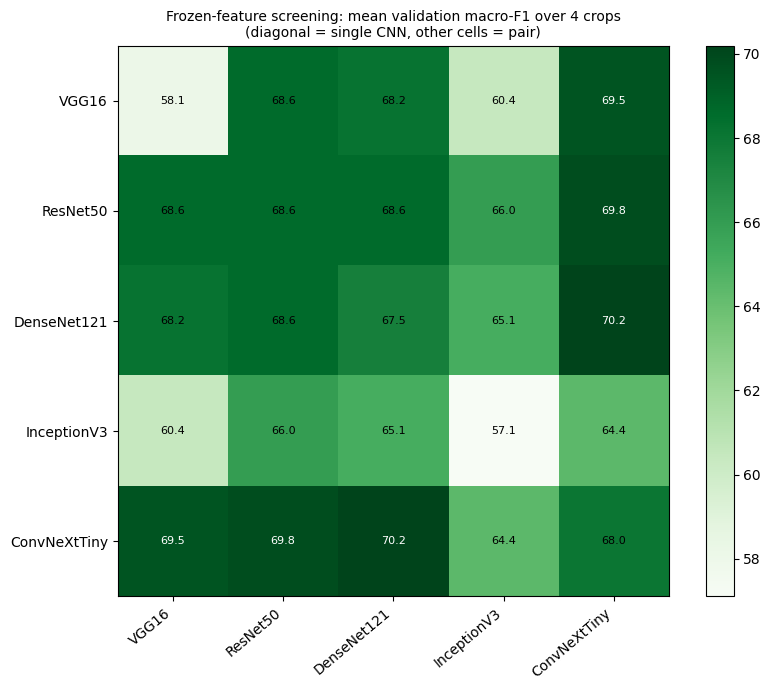

In [9]:
import matplotlib.pyplot as plt
M = pd.DataFrame(np.nan, index=MODEL_NAMES, columns=MODEL_NAMES)
for _, r in R[R.models <= 2].iterrows():
    ms = r['combo'].split(' + ')
    a, b = (ms[0], ms[0]) if len(ms) == 1 else ms
    M.loc[a, b] = M.loc[b, a] = r['VAL macro-F1 (mean)']
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(M.values, cmap='Greens')
for i in range(len(M)):
    for j in range(len(M)):
        ax.text(j, i, f'{M.values[i, j]:.1f}', ha='center', va='center', fontsize=8,
                color='white' if M.values[i, j] > np.nanpercentile(M.values, 75) else 'black')
ax.set_xticks(range(len(M)), M.columns, rotation=40, ha='right'); ax.set_yticks(range(len(M)), M.index)
ax.set_title('Frozen-feature screening: mean validation macro-F1 over 4 crops\n(diagonal = single CNN, other cells = pair)', fontsize=10)
plt.colorbar(im, fraction=0.046); plt.tight_layout()
(PROJECT / 'figures').mkdir(exist_ok=True)
fig.savefig(PROJECT / 'figures' / 'screening_pairs_heatmap.png', dpi=200); plt.show()